In [2]:
import warnings

# Suppress all warnings
warnings.filterwarnings('ignore')

# Suppress specific pandas deprecation warnings if needed
import pandas as pd
pd.options.mode.chained_assignment = None

In [3]:
!pip install yfinance

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


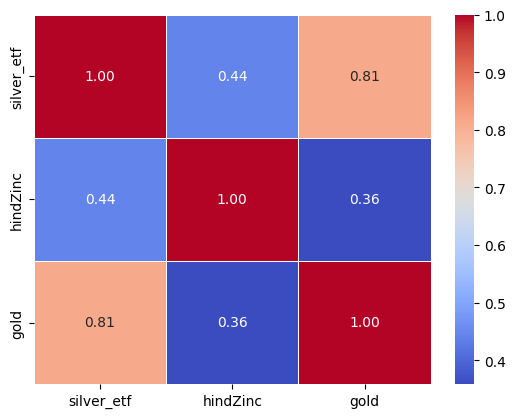

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import yfinance as yf
from datetime import date

def data(Ticker  , start , end) :
  x = yf.download(Ticker , start , end , multi_level_index=False)
  x = x.dropna()
  return x

def daily_returns(df) :
  df['dr'] = df['Close'].pct_change()
  return df['dr']

df1 = data('SILVERBEES.NS' , '2023-01-01' , date.today())
df2 = data('HINDZINC.NS' , '2023-01-01' , date.today())
df3 = data('GOLD1.NS' , '2023-01-01' , date.today())
df4 = data('^NSEI' , '2023-01-01' , date.today())

x = {
    'silver_etf' : daily_returns(df1) ,
    'hindZinc' : daily_returns(df2) ,
    'gold' : daily_returns(df3)
}

dr_table = pd.DataFrame(x)
corr_matrix = dr_table.corr()

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm",fmt=".2f" , linewidths=0.5)
plt.show()

In [5]:
# N -> total trading days
# rt -> return of that day

# geometric annual return (CAGR)
# Rann =(( prod(1 to N)(1+rt) ) ^ (252 / N)) - 1

# annual volatility
# ann_vol = (std of all returns) * sqrt(252)

# sharpe ratio
# Rf -> risk-free rate
# SR = (Rann - Rf) / ann_vol

rf = 0.065

N = dr_table.shape[0]

Rann = ((1 + dr_table).prod() ** (252/N)) - 1

ann_vol = dr_table.std() * np.sqrt(252)

SR = (Rann - rf) / ann_vol

Rann = Rann.rename("Annual returns").sort_values(ascending = False)
ann_vol = ann_vol.rename("Annual volatility").sort_values(ascending = False)
SR = SR.rename("Sharpe Ratio").sort_values(ascending = False)

print(Rann , ann_vol , SR , sep = '\n')

silver_etf    0.245464
gold          0.244949
hindZinc      0.213816
Name: Annual returns, dtype: float64
hindZinc      0.384718
silver_etf    0.365577
gold          0.203016
Name: Annual volatility, dtype: float64
gold          0.886379
silver_etf    0.493642
hindZinc      0.386818
Name: Sharpe Ratio, dtype: float64


In [6]:
#Normalize all prices to 100 at the start date and compare their growth.

x = {
    'silver_etf' : df1['Close'] ,
    'hindZinc' : df2['Close'] ,
    'gold' : df3['Close']
}

prices = pd.DataFrame(x)
prices
dr_norm = (prices * (100/prices.iloc[0]))
dr_norm

,silver_etf,hindZinc,gold
Date,,,
2023-01-02,100.000000,100.000000,100.000000
2023-01-03,101.477760,102.014750,100.800845
2023-01-04,101.566433,102.137796,101.685984
2023-01-05,98.891680,103.875741,101.032661
2023-01-06,98.832568,102.368489,100.526870
...,...,...,...
2026-11-12,253.243682,224.708947,239.620643
2026-11-13,249.386728,219.758102,237.808208
2026-11-16,237.342995,217.916403,234.099052


In [7]:
#Compare each stock against ^NSEI and compute its beta.

nifty_ret = df4['Close'].pct_change()

dr_table = dr_table.assign(nifty = nifty_ret).dropna()

dr_cov = dr_table.cov()
beta = dr_cov['nifty'] / dr_table['nifty'].var()
print(beta)

silver_etf    0.543417
hindZinc      1.036413
gold          0.227999
nifty         1.000000
Name: nifty, dtype: float64


In [10]:
#Build an equal-weight portfolio and compare its volatility with the average of the individual volatilities (diversification effect).
dr_table['equi_weight'] = 1/3 *(dr_table['silver_etf'] + dr_table['hindZinc'] + dr_table['gold'])
equi_vol = dr_table['equi_weight'].std()
avg_vol = 1/3 *(dr_table['silver_etf'].std() + dr_table['hindZinc'].std() + dr_table['gold'].std())

print("equi_vol:",equi_vol)
print("avg_vol:",avg_vol )

equi_vol: 0.01668328811321473
avg_vol: 0.02011849941777611
